# **BEiTModel**

**Mount Drive & Install Packages**

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install required packages
!pip install split-folders transformers timm torchmetrics
!pip install --upgrade accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.6/962.6 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 70.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 65.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 64.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstal

**imports**

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
import timm
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform
from transformers import BeitFeatureExtractor, BeitForImageClassification
from torchmetrics import Accuracy, Precision, Recall, F1Score, AUROC
import splitfolders

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


**Dataset Splitting**

In [ ]:
# Dataset splitting
# Define paths
unsplit_path = "/content/drive/MyDrive/artstyleproject/processeddataset_classification2"
output_path = "/content/processeddataset_classification22"

# Verify and split dataset
if not os.path.exists(unsplit_path):
    print(f"Error: Path not found - {unsplit_path}")
    print("Available folders in /content/drive/MyDrive:")
    !ls "/content/drive/MyDrive"
else:
    print("Dataset found successfully!")
    splitfolders.ratio(
        input=unsplit_path,
        output=output_path,
        seed=42,
        ratio=(0.6, 0.2, 0.2),
        group_prefix=None,
        move=False
    )

Dataset found successfully!


Copying files: 52094 files [24:21, 35.63 files/s] 


**Data Loading & Transforms**

In [ ]:
# Define paths for train, validation, and test sets
train_dir = os.path.join(output_path, 'train')
val_dir = os.path.join(output_path, 'val')
test_dir = os.path.join(output_path, 'test')

# Define transforms
# BEiT specific transforms
beit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Create datasets
train_dataset = ImageFolder(root=train_dir, transform=beit_transform)
val_dataset = ImageFolder(root=val_dir, transform=beit_transform)
test_dataset = ImageFolder(root=test_dir, transform=beit_transform)

# Split validation set to create plotting_test set
val_size = len(val_dataset)
val_indices = list(range(val_size))
val_split = int(val_size * 0.7)  # 70% for validation, 30% for plotting

val_subset = Subset(val_dataset, val_indices[:val_split])
plotting_test_subset = Subset(val_dataset, val_indices[val_split:])

# Create data loaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=4)
plotting_test_loader = DataLoader(plotting_test_subset, batch_size=batch_size, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Print dataset sizes
print(f"Training set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_subset)}")
print(f"Plotting test set size: {len(plotting_test_subset)}")
print(f"Real test set size: {len(test_dataset)}")

# Class names
class_names = train_dataset.classes
print("Class names:", class_names)

Training set size: 31255
Validation set size: 7291
Plotting test set size: 3126
Real test set size: 10422
Class names: ['baroque', 'expressionism', 'impressionism', 'realism', 'romanticism']


/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


**Model Initialization**

In [ ]:
# Initialize BEiT model
model_name = "microsoft/beit-base-patch16-224"
model = BeitForImageClassification.from_pretrained(
    model_name,
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

# Move model to device
model = model.to(device)

# Print model architecture
print(model)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/69.9k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/350M [00:00<?, ?B/s]

Some weights of BeitForImageClassification were not initialized from the model checkpoint at microsoft/beit-base-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([5]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 768]) in the checkpoint and torch.Size([5, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BeitForImageClassification(
  (beit): BeitModel(
    (embeddings): BeitEmbeddings(
      (patch_embeddings): BeitPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): BeitEncoder(
      (layer): ModuleList(
        (0): BeitLayer(
          (attention): BeitAttention(
            (attention): BeitSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
              (relative_position_bias): BeitRelativePositionBias()
            )
            (output): BeitSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          

**Training Setup**

In [ ]:
# Define optimizer and loss function
optimizer = optim.AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

# Define metrics
accuracy = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)
precision = Precision(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
recall = Recall(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
f1 = F1Score(task="multiclass", average='macro', num_classes=len(class_names)).to(device)
auroc = AUROC(task="multiclass", num_classes=len(class_names)).to(device)

**Training Function**

In [ ]:
# Training function
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    best_val_loss = float('inf')
    best_model_weights = None

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        running_corrects = 0

        # Training phase
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs).logits
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc.cpu())

        # Validation phase
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_weights = model.state_dict().copy()

        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')
        print('-' * 10)

    training_time = time.time() - start_time
    print(f'Training complete in {training_time // 60:.0f}m {training_time % 60:.0f}s')
    print(f'Best val Loss: {best_val_loss:.4f}')

    # Load best model weights
    model.load_state_dict(best_model_weights)

    return model, train_losses, val_losses, train_accs, val_accs, training_time

# Evaluation function
def evaluate_model(model, data_loader, criterion):
    model.eval()
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == labels.data)

    loss = running_loss / len(data_loader.dataset)
    acc = running_corrects.double() / len(data_loader.dataset)

    return loss, acc.cpu()

**Model Training**

In [ ]:
# Train the model
num_epochs = 10
trained_model, train_losses, val_losses, train_accs, val_accs, training_time = train_model(
    model, train_loader, val_loader, criterion, optimizer, num_epochs
)

Epoch 1/10:
Train Loss: 0.6411 Acc: 0.7542
Val Loss: 0.3510 Acc: 0.8645
----------
Epoch 2/10:
Train Loss: 0.2494 Acc: 0.9143
Val Loss: 0.2654 Acc: 0.9025
----------
Epoch 3/10:
Train Loss: 0.0941 Acc: 0.9711
Val Loss: 0.2377 Acc: 0.9194
----------
Epoch 4/10:
Train Loss: 0.0556 Acc: 0.9830
Val Loss: 0.1930 Acc: 0.9372
----------
Epoch 5/10:
Train Loss: 0.0443 Acc: 0.9861
Val Loss: 0.2981 Acc: 0.9065
----------
Epoch 6/10:
Train Loss: 0.0358 Acc: 0.9877
Val Loss: 0.2448 Acc: 0.9285
----------
Epoch 7/10:
Train Loss: 0.0362 Acc: 0.9884
Val Loss: 0.1575 Acc: 0.9546
----------
Epoch 8/10:
Train Loss: 0.0253 Acc: 0.9916
Val Loss: 0.2396 Acc: 0.9357
----------
Epoch 9/10:
Train Loss: 0.0310 Acc: 0.9896
Val Loss: 0.2282 Acc: 0.9377
----------
Epoch 10/10:
Train Loss: 0.0277 Acc: 0.9910
Val Loss: 0.1940 Acc: 0.9449
----------
Training complete in 197m 11s
Best val Loss: 0.1575


**Training Curves**

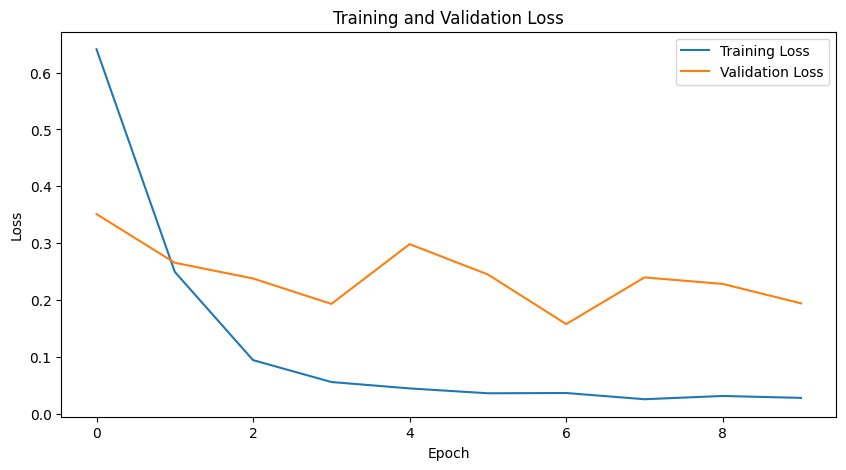

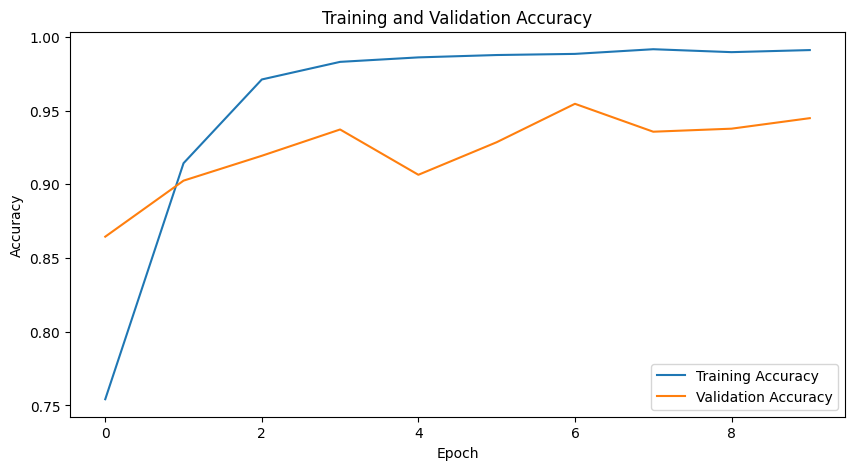

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(10, 5))
plt.plot([acc.item() for acc in train_accs], label='Training Accuracy')
plt.plot([acc.item() for acc in val_accs], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

**Testing & Metrics**

In [ ]:
# Test the model on test set
def test_model(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs).logits
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return all_labels, all_preds, all_probs

# Measure inference time
start_time = time.time()
test_labels, test_preds, test_probs = test_model(trained_model, test_loader)
inference_time = time.time() - start_time
print(f"Inference time for test set: {inference_time:.2f} seconds")

# Calculate metrics
accuracy = accuracy(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
precision = precision(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
recall = recall(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
f1 = f1(torch.tensor(test_preds).to(device), torch.tensor(test_labels).to(device))
auroc = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"AUROC: {auroc:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=class_names))

Inference time for test set: 169.96 seconds


/tmp/ipython-input-11-1987898748.py:34: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  auroc = auroc(torch.tensor(test_probs).to(device), torch.tensor(test_labels).to(device))


Accuracy: 0.9351
Precision: 0.9355
Recall: 0.9350
F1 Score: 0.9349
AUROC: 0.9937

Classification Report:
               precision    recall  f1-score   support

      baroque       0.96      0.96      0.96      2073
expressionism       0.97      0.96      0.96      2101
impressionism       0.92      0.95      0.94      2093
      realism       0.93      0.87      0.90      2070
  romanticism       0.90      0.94      0.92      2085

     accuracy                           0.94     10422
    macro avg       0.94      0.94      0.93     10422
 weighted avg       0.94      0.94      0.93     10422



**Confusion Matrix**

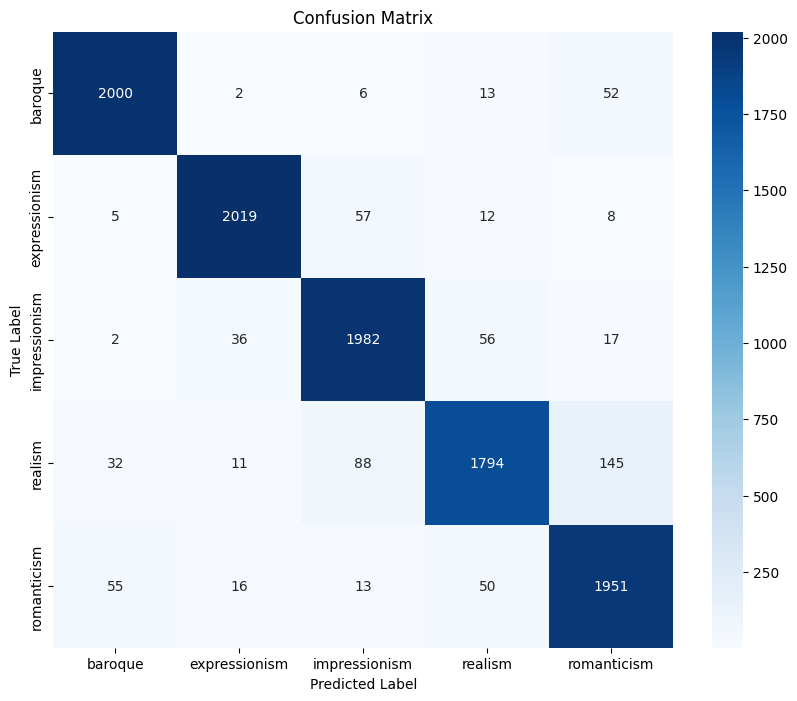

In [ ]:
# Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, classes, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(test_labels, test_preds, class_names)

**ROC Curve**

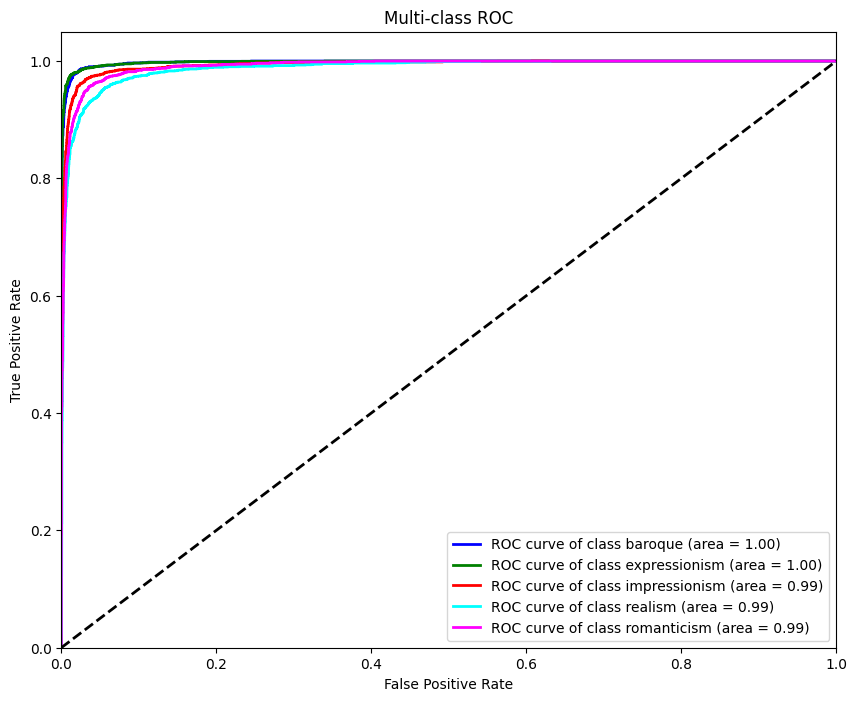

In [ ]:
# ROC Curve
def plot_roc_curve(y_true, y_probs, classes):
    # Binarize the output
    y_true_bin = label_binarize(y_true, classes=np.arange(len(classes)))

    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], np.array(y_probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot all ROC curves
    plt.figure(figsize=(10, 8))
    colors = ['blue', 'green', 'red', 'cyan', 'magenta']
    for i, color in zip(range(len(classes)), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='ROC curve of class {0} (area = {1:0.2f})'
                 ''.format(classes[i], roc_auc[i]))

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class ROC')
    plt.legend(loc="lower right")
    plt.show()

plot_roc_curve(test_labels, test_probs, class_names)

**Save Results**

In [ ]:
# Save model and metrics
results = {
    'model': 'BEiT',
    'training_time': training_time,
    'inference_time': inference_time,
    'accuracy': accuracy.item(),
    'precision': precision.item(),
    'recall': recall.item(),
    'f1_score': f1.item(),
    'auroc': auroc.item(),
    'num_epochs': num_epochs,
    'batch_size': batch_size,
    'classes': class_names
}

# Save results to dataframe
results_df = pd.DataFrame([results])
print(results_df)

# Save to CSV
results_df.to_csv('beit_results.csv', index=False)

# Save model
torch.save(trained_model.state_dict(), 'beit_art_classifier.pth')

  model  training_time  inference_time  accuracy  precision    recall  \
0  BEiT   11831.341362      169.960714  0.935137   0.935457  0.935024   

   f1_score     auroc  num_epochs  batch_size  \
0  0.934888  0.993733          10          32   

                                             classes  
0  [baroque, expressionism, impressionism, realis...  


**Sample Predictions**

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


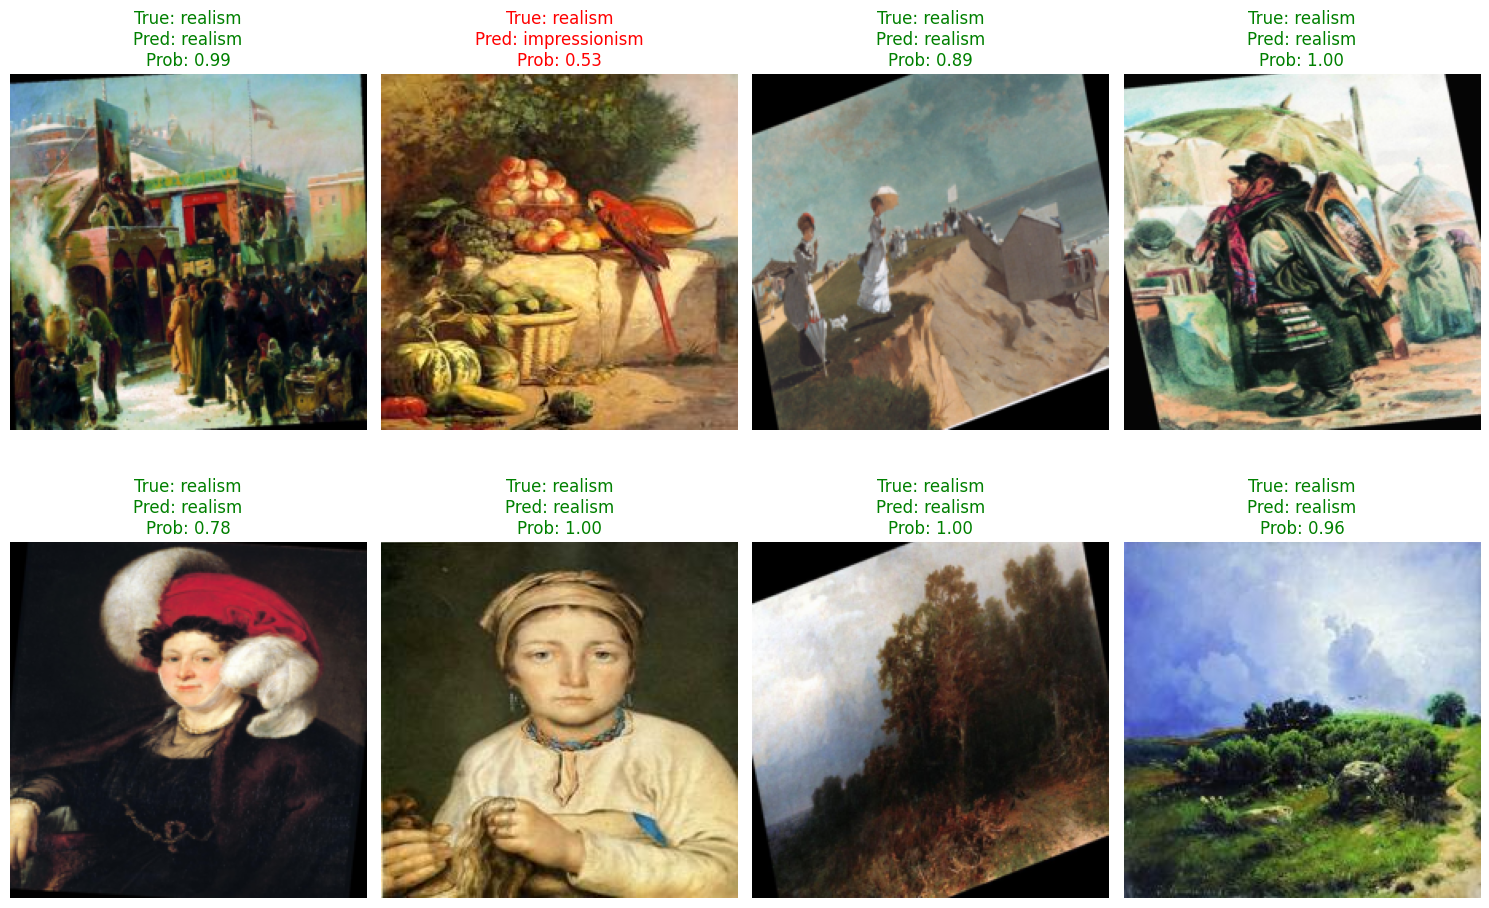

In [ ]:
# Plot sample predictions
def plot_sample_predictions(model, data_loader, class_names, num_samples=8):
    model.eval()
    images, labels = next(iter(data_loader))
    images = images.to(device)
    labels = labels.to(device)

    with torch.no_grad():
        outputs = model(images).logits
        _, preds = torch.max(outputs, 1)
        probs = torch.softmax(outputs, dim=1)

    images = images.cpu()
    labels = labels.cpu()
    preds = preds.cpu()
    probs = probs.cpu()

    plt.figure(figsize=(15, 10))
    for i in range(num_samples):
        plt.subplot(2, 4, i+1)
        img = images[i].permute(1, 2, 0).numpy()
        img = (img - img.min()) / (img.max() - img.min())  # Normalize to [0,1] for display

        plt.imshow(img)
        true_label = class_names[labels[i]]
        pred_label = class_names[preds[i]]
        prob = probs[i][preds[i]].item()

        title = f'True: {true_label}\nPred: {pred_label}\nProb: {prob:.2f}'
        if pred_label == true_label:
            plt.title(title, color='green')
        else:
            plt.title(title, color='red')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_predictions(trained_model, plotting_test_loader, class_names)